# Compute UMAPs outside of model training pipeline

Extract the key UMAP functions from the OOP framework so that I can compute for any data.

In [2]:
from os.path import join
from tqdm import tqdm
import numpy as np
import random
import torch
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib
import seaborn as sns
from adjustText import adjust_text

from cytoself.analysis.analysis_opencell import AnalysisOpenCell
from cytoself.datamanager.opencell import DataManagerOpenCell
from cytoself.trainer.cytoselflite_trainer import CytoselfFullTrainer
from cytoself.trainer.utils.plot_history import plot_history_cytoself
from cytoself.analysis.utils.cluster_score import calculate_cluster_centrosize

random.seed(42)
np.random.seed(42)

/home/shenrunx/software/anaconda3/envs/cytoself/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
datapath = '../model_inputs/2024_01-02_Batch_7-8'
outputpath = "../trained_models/varchamp_b78"
model_nm = "model_30.pt"
data_ch = ['pro', 'nuc']
device="cuda:0"
model_path = f"{outputpath}/{model_nm}"

In [ ]:
# datamanager = DataManagerOpenCell(datapath, data_ch, fov_col=None)
# datamanager.const_dataloader(batch_size=64, label_name_position=1)

Loading pro data...


100%|██████████| 917/917 [02:16<00:00,  6.73it/s]


Loading nuc data...


100%|██████████| 917/917 [02:19<00:00,  6.56it/s]


Loading label data...


100%|██████████| 917/917 [00:00<00:00, 5645.59it/s]


Splitting data...
Computing variance of training data...
Computing variance of validation data...
Computing variance of test data...


In [5]:
# model_args = {
#     "input_shape": (2, 100, 100),
#     "emb_shapes": ((25, 25), (4, 4)),
#     "output_shape": (2, 100, 100),
#     "fc_output_idx": [2],
#     "vq_args": {"num_embeddings": 512, "embedding_dim": 64},
#     "num_class": len(datamanager.unique_labels),
#     "fc_input_type": "vqvec",
# }

# train_args = {
#     "lr": 0.0004,
#     "max_epoch": 100,
#     "reducelr_patience": 4,
#     "reducelr_increment": 0.1,
#     "earlystop_patience": 12,
# }

In [7]:
trainer = CytoselfFullTrainer(train_args, homepath=outputpath, model_args=model_args)

# modified ../cytoself/trainer/basetrainer.py due to the following error:
# File ~/igvf/varchamp/2025_laval_submitted/2_individual_assay_results/imaging/2_analysis/3_cytoself/cytoself/trainer/basetrainer.py:550, in BaseTrainer.load_model(self, path, by_weights)
#     537 def load_model(self, path: str, by_weights: bool = True) -> None:
#     538     """
#     539     Load a pytorch model
#     540 
#    (...)
#     548 
#     549     """
# --> 550     _model = torch.load(path)
# UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, do those steps only if you trust the source of the checkpoint. 
# 	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
# `weights_only = False` added.

trainer.load_model(model_path)

A model has been loaded from ../trained_models/varchamp_b78/model_30.pt


In [ ]:
## infer embeddings
test_embeddings = trainer.infer_embeddings(datamanager.test_loader)

if isinstance(test_embeddings, tuple) and len(test_embeddings) > 1:
    test_embeddings = test_embeddings[0]

savepath_embeddings = trainer.savepath_dict["embeddings"]
# np.save(join(savepath_embeddings, 'embeddings_testdata.npy'), test_embeddings)

Infer: 100%|██████████| 1046/1046 [00:19<00:00, 53.24it/s]


In [ ]:
# infer embeddings for training data 
train_embeddings = trainer.infer_embeddings(datamanager.train_loader)
if isinstance(train_embeddings, tuple) and len(train_embeddings) > 1:
    train_embeddings = train_embeddings[0]

savepath_embeddings = trainer.savepath_dict["embeddings"]
# np.save(join(savepath_embeddings, 'embeddings_traindata.npy'), train_embeddings)

Infer: 100%|██████████| 10458/10458 [05:02<00:00, 34.56it/s]


In [ ]:
# infer embeddings for training data 
valid_embeddings = trainer.infer_embeddings(datamanager.val_loader)
if isinstance(valid_embeddings, tuple) and len(valid_embeddings) > 1:
    valid_embeddings = valid_embeddings[0]

savepath_embeddings = trainer.savepath_dict["embeddings"]
# np.save(join(savepath_embeddings, 'embeddings_valdata.npy'), valid_embeddings)

Infer: 100%|██████████| 1250/1250 [00:37<00:00, 33.73it/s]


In [16]:
# # save labels by data
# train_labels = datamanager.train_loader.dataset.label
# np.save(join(savepath_embeddings, 'labels_traindata.npy'), train_labels)

# val_labels = datamanager.val_loader.dataset.label
# np.save(join(savepath_embeddings, 'labels_valdata.npy'), val_labels)

# test_labels = datamanager.test_loader.dataset.label
# np.save(join(savepath_embeddings, 'labels_testdata.npy'), test_labels)

In [18]:
import umap.umap_ as umap
import matplotlib.colors as mcolors
import matplotlib

n_neighbors=15
min_dist=0.1
metric='euclidean'
verbose=True

In [ ]:
reducer = umap.UMAP(n_components=2, n_neighbors=n_neighbors, min_dist=min_dist, metric=metric, verbose=verbose, random_state=42)
umap_data = reducer.fit_transform(test_embeddings.reshape(test_embeddings.shape[0], -1))
labels = datamanager.test_loader.dataset.label
umap_df = pl.DataFrame({
    "Metadata_Protein": list(labels[:, 0]),
    "Metadata_CellID": list(labels[:, 1]),
    "Comp1": umap_data[:, 0],
    "Comp2": umap_data[:, 1]
})
# umap_df.write_parquet(f"{outputpath}/analysis/umap_data/umap_comps_testdata.parquet")

UMAP(random_state=42, verbose=True)
Mon Apr 14 14:40:30 2025 Construct fuzzy simplicial set
Mon Apr 14 14:40:30 2025 Finding Nearest Neighbors
Mon Apr 14 14:40:30 2025 Building RP forest with 18 trees
Mon Apr 14 14:40:31 2025 NN descent for 16 iterations
	 1  /  16
	 2  /  16
	 3  /  16
	 4  /  16
	Stopping threshold met -- exiting after 4 iterations
Mon Apr 14 14:40:37 2025 Finished Nearest Neighbor Search
Mon Apr 14 14:40:37 2025 Construct embedding


Epochs completed: 100%| ██████████ 200/200 [00:25]


Mon Apr 14 14:41:05 2025 Finished embedding


In [ ]:
reducer = umap.UMAP(n_components=2, n_neighbors=n_neighbors, min_dist=min_dist, metric=metric, verbose=verbose, random_state=42)
umap_data = reducer.fit_transform(valid_embeddings.reshape(valid_embeddings.shape[0], -1))
labels = datamanager.val_loader.dataset.label
umap_df = pl.DataFrame({
    "Metadata_Protein": list(labels[:, 0]),
    "Metadata_CellID": list(labels[:, 1]),
    "Comp1": umap_data[:, 0],
    "Comp2": umap_data[:, 1]
})
# umap_df.write_parquet(f"{outputpath}/analysis/umap_data/umap_comps_valdata.parquet")

UMAP(random_state=42, verbose=True)
Mon Apr 14 14:41:06 2025 Construct fuzzy simplicial set
Mon Apr 14 14:41:06 2025 Finding Nearest Neighbors
Mon Apr 14 14:41:06 2025 Building RP forest with 19 trees
Mon Apr 14 14:41:07 2025 NN descent for 16 iterations
	 1  /  16
	 2  /  16
	 3  /  16
	 4  /  16
	Stopping threshold met -- exiting after 4 iterations
Mon Apr 14 14:41:14 2025 Finished Nearest Neighbor Search
Mon Apr 14 14:41:14 2025 Construct embedding


Epochs completed: 100%| ██████████ 200/200 [00:30]


Mon Apr 14 14:41:48 2025 Finished embedding


## Just plot UMAPs

In [6]:
def get_custom_colormap(num_colors, first_color='#D3D3D3'):
    # Generate a colormap with the specified number of colors
    # cmap = plt.get_cmap('tab10', num_colors)
    # Generate a color palette with 25 distinct colors using the 'cubehelix' system
    palette = sns.color_palette("husl", num_colors)
    colors = palette # [first_color]
    # colors += [c for c in palette if c != first_color]
    # Replace the first color with light grey
    return colors

In [7]:
trainer_embeddings = np.load(join(f"{outputpath}/embeddings", 'embeddings_traindata.npy'))
val_embeddings = np.load(join(f"{outputpath}/embeddings", 'embeddings_valdata.npy'))
tester_embeddings = np.load(join(f"{outputpath}/embeddings", 'embeddings_testdata.npy'))

train_labels = np.load(join(f"{outputpath}/embeddings", 'labels_traindata.npy'), allow_pickle=True)
val_labels = np.load(join(f"{outputpath}/embeddings", 'labels_valdata.npy'), allow_pickle=True)
test_labels = np.load(join(f"{outputpath}/embeddings", 'labels_testdata.npy'), allow_pickle=True)

In [10]:
tester_embeddings.reshape(tester_embeddings.shape[0], -1).shape

(66931, 1024)

In [27]:
print(trainer_embeddings.shape)
print(val_embeddings.shape)
print(tester_embeddings.shape)

print(train_labels.shape)
print(val_labels.shape)
print(test_labels.shape)

(669302, 64, 4, 4)
(79989, 64, 4, 4)
(66931, 64, 4, 4)
(669302, 2)
(79989, 2)
(66931, 2)


In [29]:
669302 + 79989 + 66931

816222

### Loading UMAP embeddings

In [12]:
umap_df = pl.read_parquet(f"{outputpath}/analysis/umap_data/umap_comps_testdata.parquet")
umap_df = umap_df.with_columns(
    pl.col("Metadata_CellID").str.slice(11,2).alias("batch"),
    pl.col("Metadata_CellID").str.slice(23,3).alias("well_position"),
    pl.col("Metadata_Protein").str.split(by="-").list.get(0).alias("Gene"),
    (pl.when(pl.col("Metadata_Protein").str.contains("-"))
    .then(pl.lit("Allele"))
    .otherwise(pl.lit("Reference"))).alias("Allele_type")
)
umap_df

Metadata_Protein,Metadata_CellID,Comp1,Comp2,batch,well_position,Gene,Allele_type
str,str,f32,f32,str,str,str,str
"""DMC1""","""2024_01_17_B7A1R1_P1T4_F14_120…",13.322915,-0.344944,"""B7""","""F14""","""DMC1""","""Reference"""
"""IL2RG-Arg285Gln""","""2024_01_17_B7A1R1_P2T1_M24_280…",0.596543,9.418332,"""B7""","""M24""","""IL2RG""","""Allele"""
"""ACSF3-Thr358Ile""","""2024_01_17_B7A1R1_P1T1_I05_176…",0.023272,4.490632,"""B7""","""I05""","""ACSF3""","""Allele"""
"""KCTD7-Arg184Cys""","""2024_01_17_B7A1R1_P2T2_P19_340…",9.115917,0.690628,"""B7""","""P19""","""KCTD7""","""Allele"""
"""PRKACB""","""2024_01_19_B7A1R1_P3T4_F20_125…",7.354819,0.579663,"""B7""","""F20""","""PRKACB""","""Reference"""
…,…,…,…,…,…,…,…
"""MVK-Leu41Pro""","""2024_01_19_B7A1R1_P3T4_K19_232…",9.064614,1.240857,"""B7""","""K19""","""MVK""","""Allele"""
"""TTR-Asp119Asn""","""2024_01_22_B7A1R1_P4T3_N11_290…",7.734474,10.93527,"""B7""","""N11""","""TTR""","""Allele"""
"""MLH1-Pro640Ser""","""2024_01_19_B7A1R1_P3T4_K09_223…",4.160758,1.399111,"""B7""","""K09""","""MLH1""","""Allele"""


#### Gene centroid

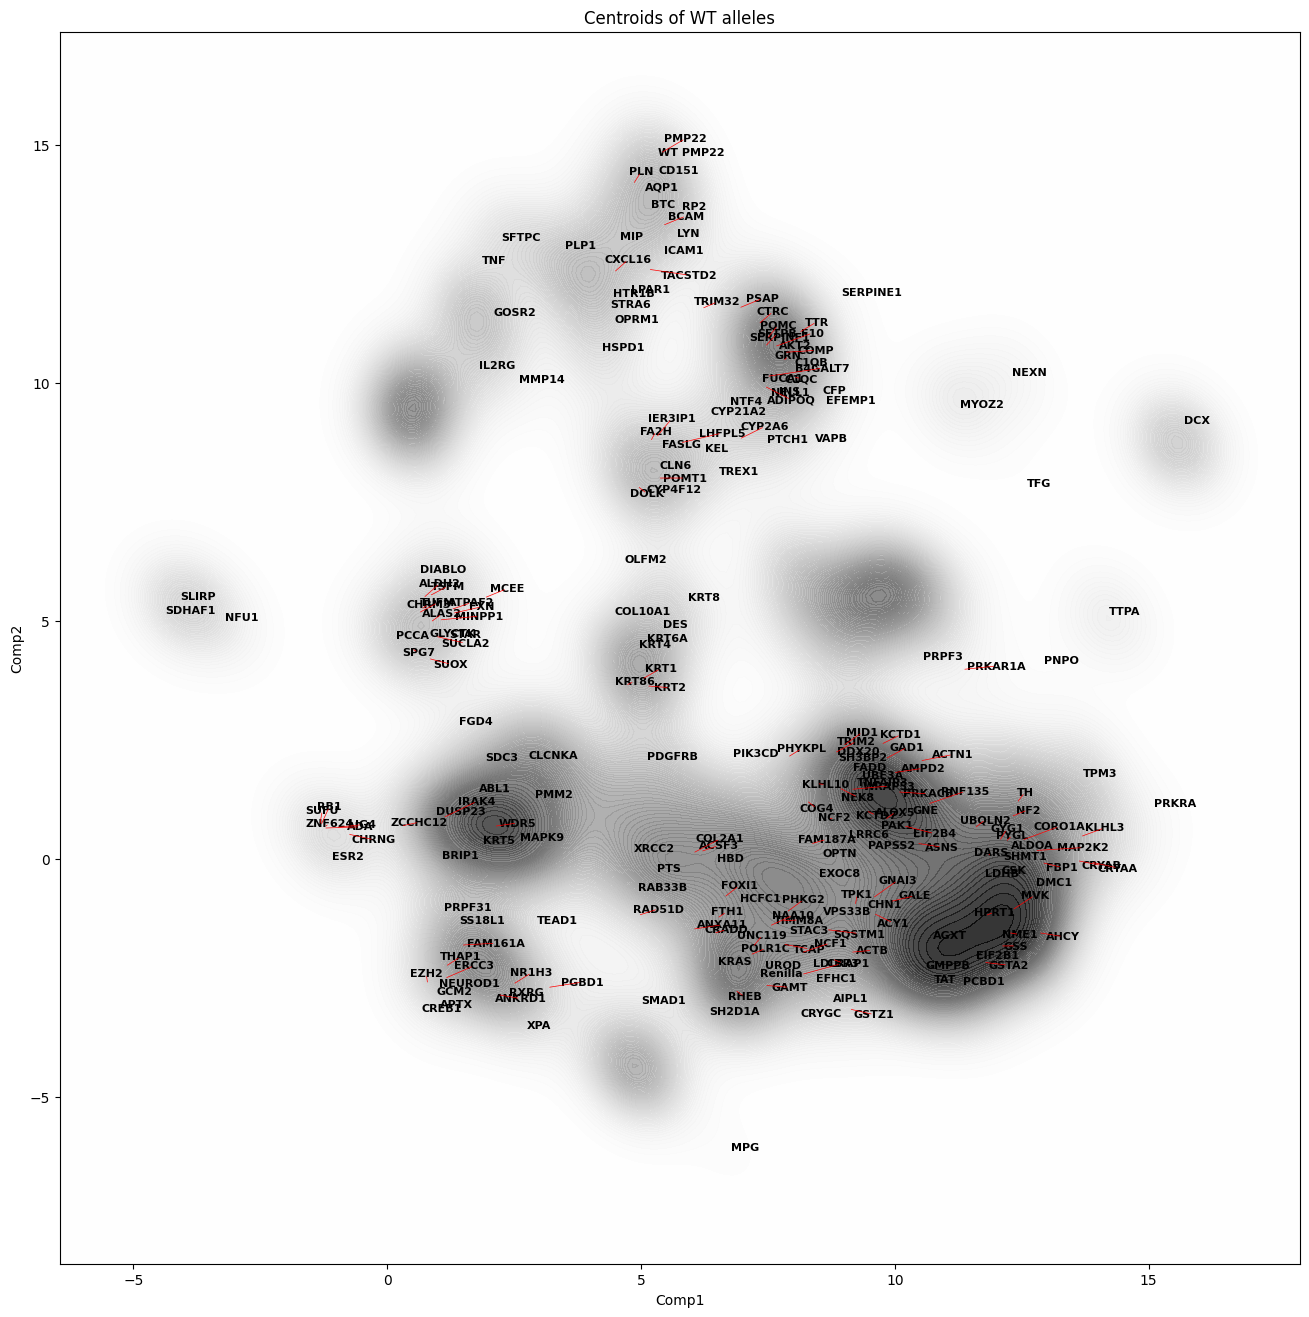

In [35]:
# Compute centroid of each WT
wt_centroid = umap_df.filter(~pl.col("Metadata_Protein").str.contains("-")).group_by("Metadata_Protein").agg([
    pl.col("Comp1").median().alias("Comp1"),
    pl.col("Comp2").median().alias("Comp2"),
])

plt.figure(figsize=(16, 16))
sns.kdeplot(data=umap_df.to_pandas(), x="Comp1", y="Comp2", fill=True, cmap="Greys", alpha=0.8, thresh=0, levels=100)

# Overlay the text labels
texts = []
for i, row in wt_centroid.to_pandas().iterrows():
    texts.append(plt.text(row["Comp1"], row["Comp2"], row["Metadata_Protein"], 
                          fontsize=8, fontweight='bold', color='black'))

# Adjust text to avoid overlaps
adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5))
plt.title("Centroids of WT alleles")
plt.savefig(f"{outputpath}/analysis/umap_figures/umap_wt_centroid_density.svg", format='svg')

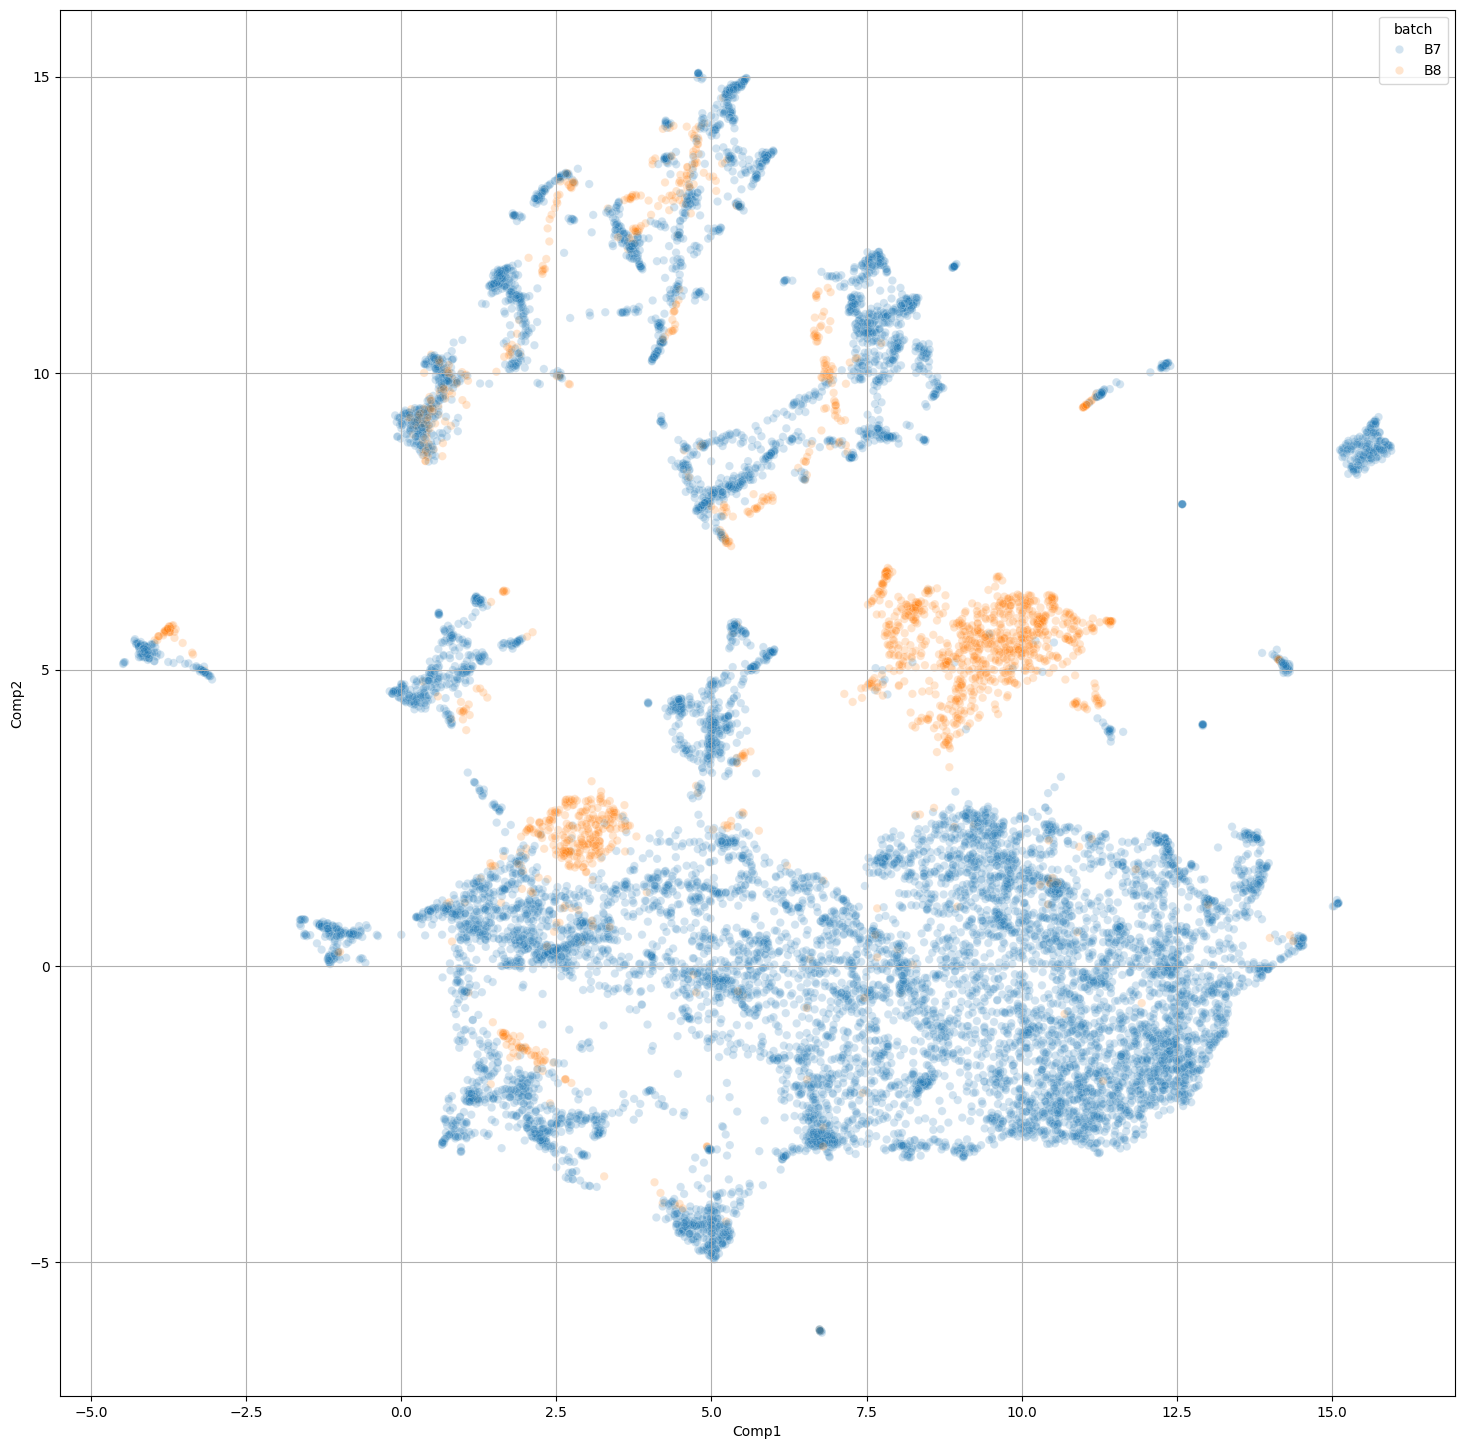

In [39]:
fig, ax = plt.subplots(1, 1, figsize=(18, 18))
sns.scatterplot(umap_df.sample(fraction=.2, shuffle=True), x="Comp1", y="Comp2", hue="batch", alpha=.2, ax=ax)
ax.grid(True)

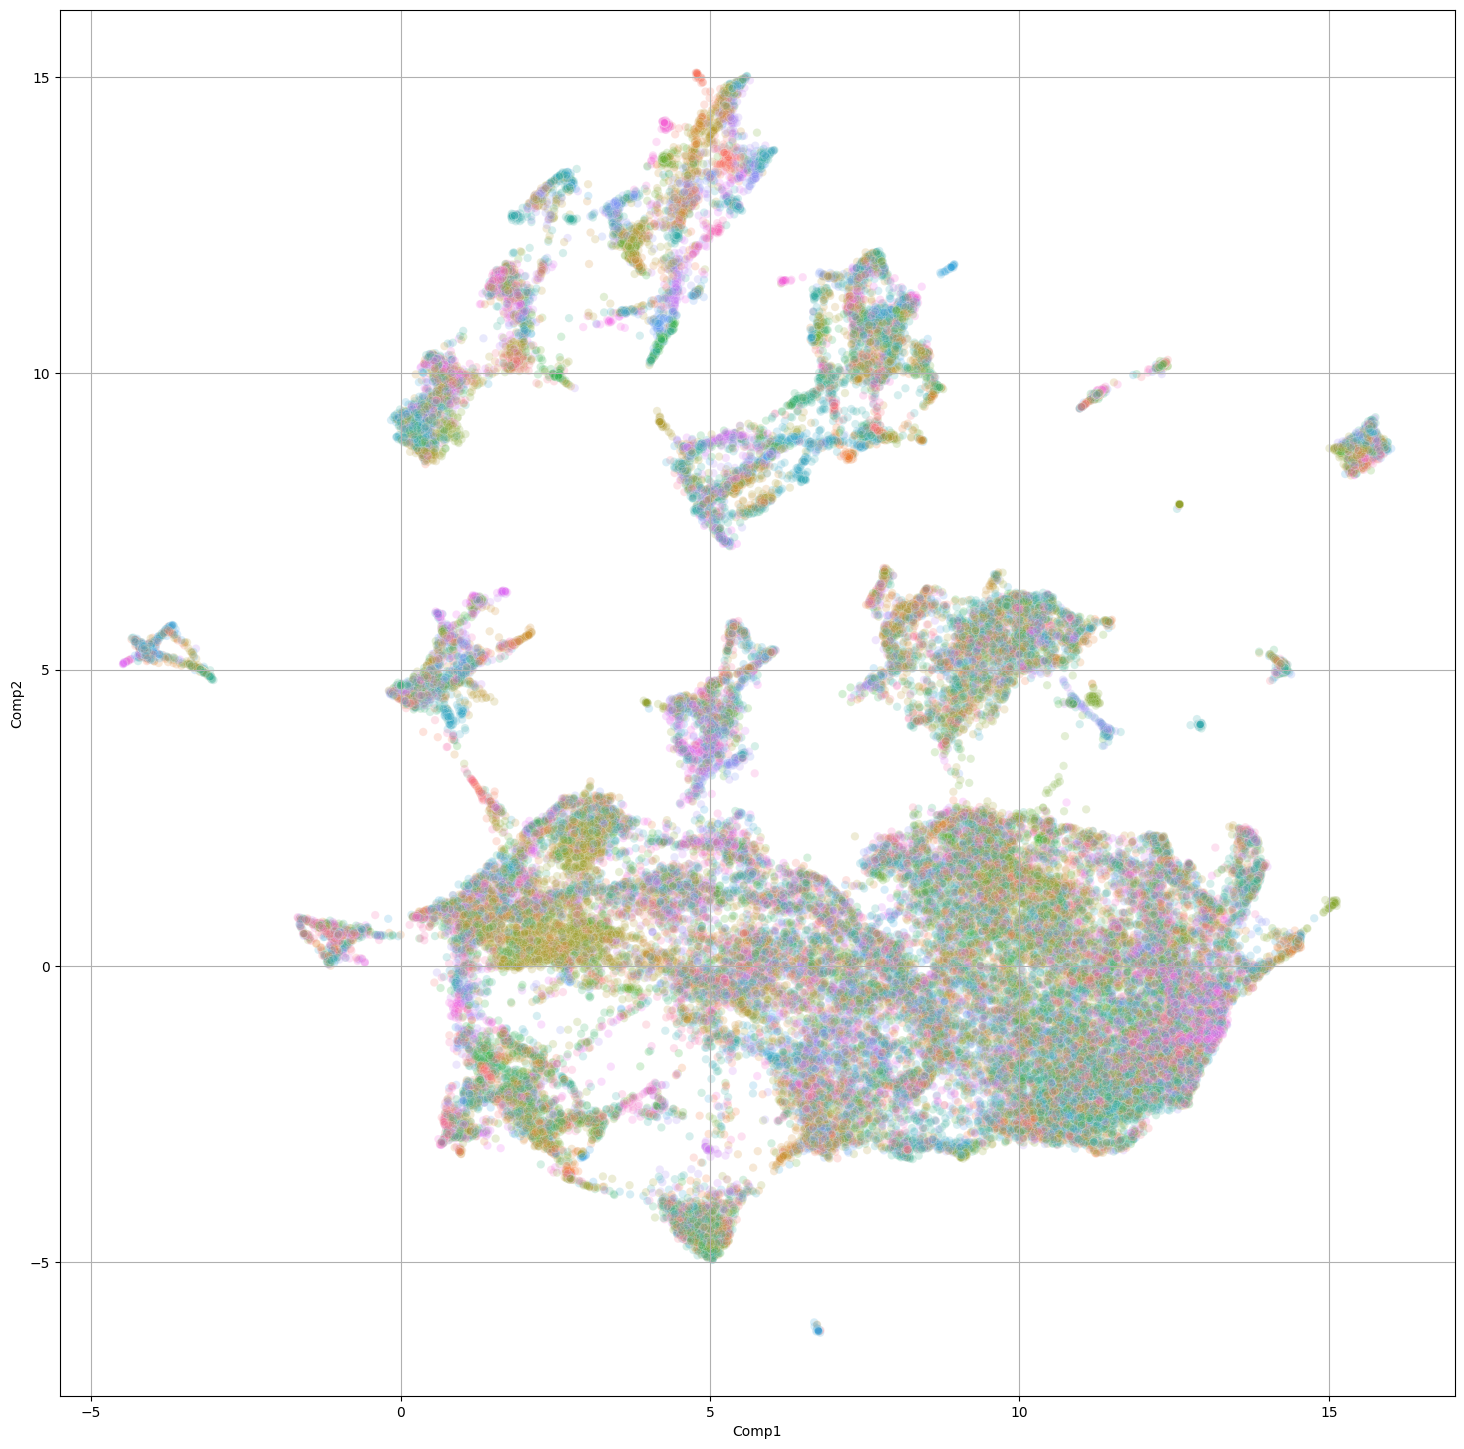

In [42]:
fig, ax = plt.subplots(1, 1, figsize=(18, 18))
sns.scatterplot(umap_df, x="Comp1", y="Comp2", hue="well_position", alpha=.2, ax=ax, color="hustl", legend=False)
ax.grid(True)

In [ ]:
# umap_df.filter((pl.col("Comp1")>10)&(pl.col("Comp1")<15)&(pl.col("Comp2")>2.5)&(pl.col("Comp2")<6)).sort(pl.col("Metadata_Protein")).select(pl.col("Metadata_Protein")).unique().sort(by="Metadata_Protein")
# umap_df.filter((pl.col("Metadata_Protein").str.contains("AGXT"))&(pl.col("batch")!="B8")).sort(pl.col("Metadata_Protein"))
# prot_count = umap_df.group_by("Metadata_Protein").agg(pl.count().alias("Frequency"))
# prot_count

Cool, illustrative examples:
- RP2: clear mislocalization of one variant. It obviously separates from the rest.
- MYOZ2: 3 variants, >80% all piled on top of each other on one very small dot.
- LDHB: 1 variant clearly different

In [44]:
def plot_gene_umap(umap_df, gene):
    fig, ax = plt.subplots(1, 1, figsize=(18, 18))
    ax.grid(True)

    umap_df = umap_df.with_columns(
        pl.when(pl.col("Metadata_Protein").str.contains(gene))
        .then(pl.col("Metadata_Protein"))
        .otherwise(pl.lit("000")).alias(f"{gene}_Variant")
    ).sort(f"{gene}_Variant")
    
    sns.scatterplot(umap_df.filter(pl.col(f"{gene}_Variant") == "000"), x="Comp1", y="Comp2", color="grey", alpha=.1, ax=ax)
    sns.scatterplot(umap_df.filter(pl.col(f"{gene}_Variant") != "000"), x="Comp1", y="Comp2", hue=f"{gene}_Variant", style="batch", palette="Set1", ax=ax, s=70, alpha=0.7)

<Axes: xlabel='Comp1', ylabel='Comp2'>

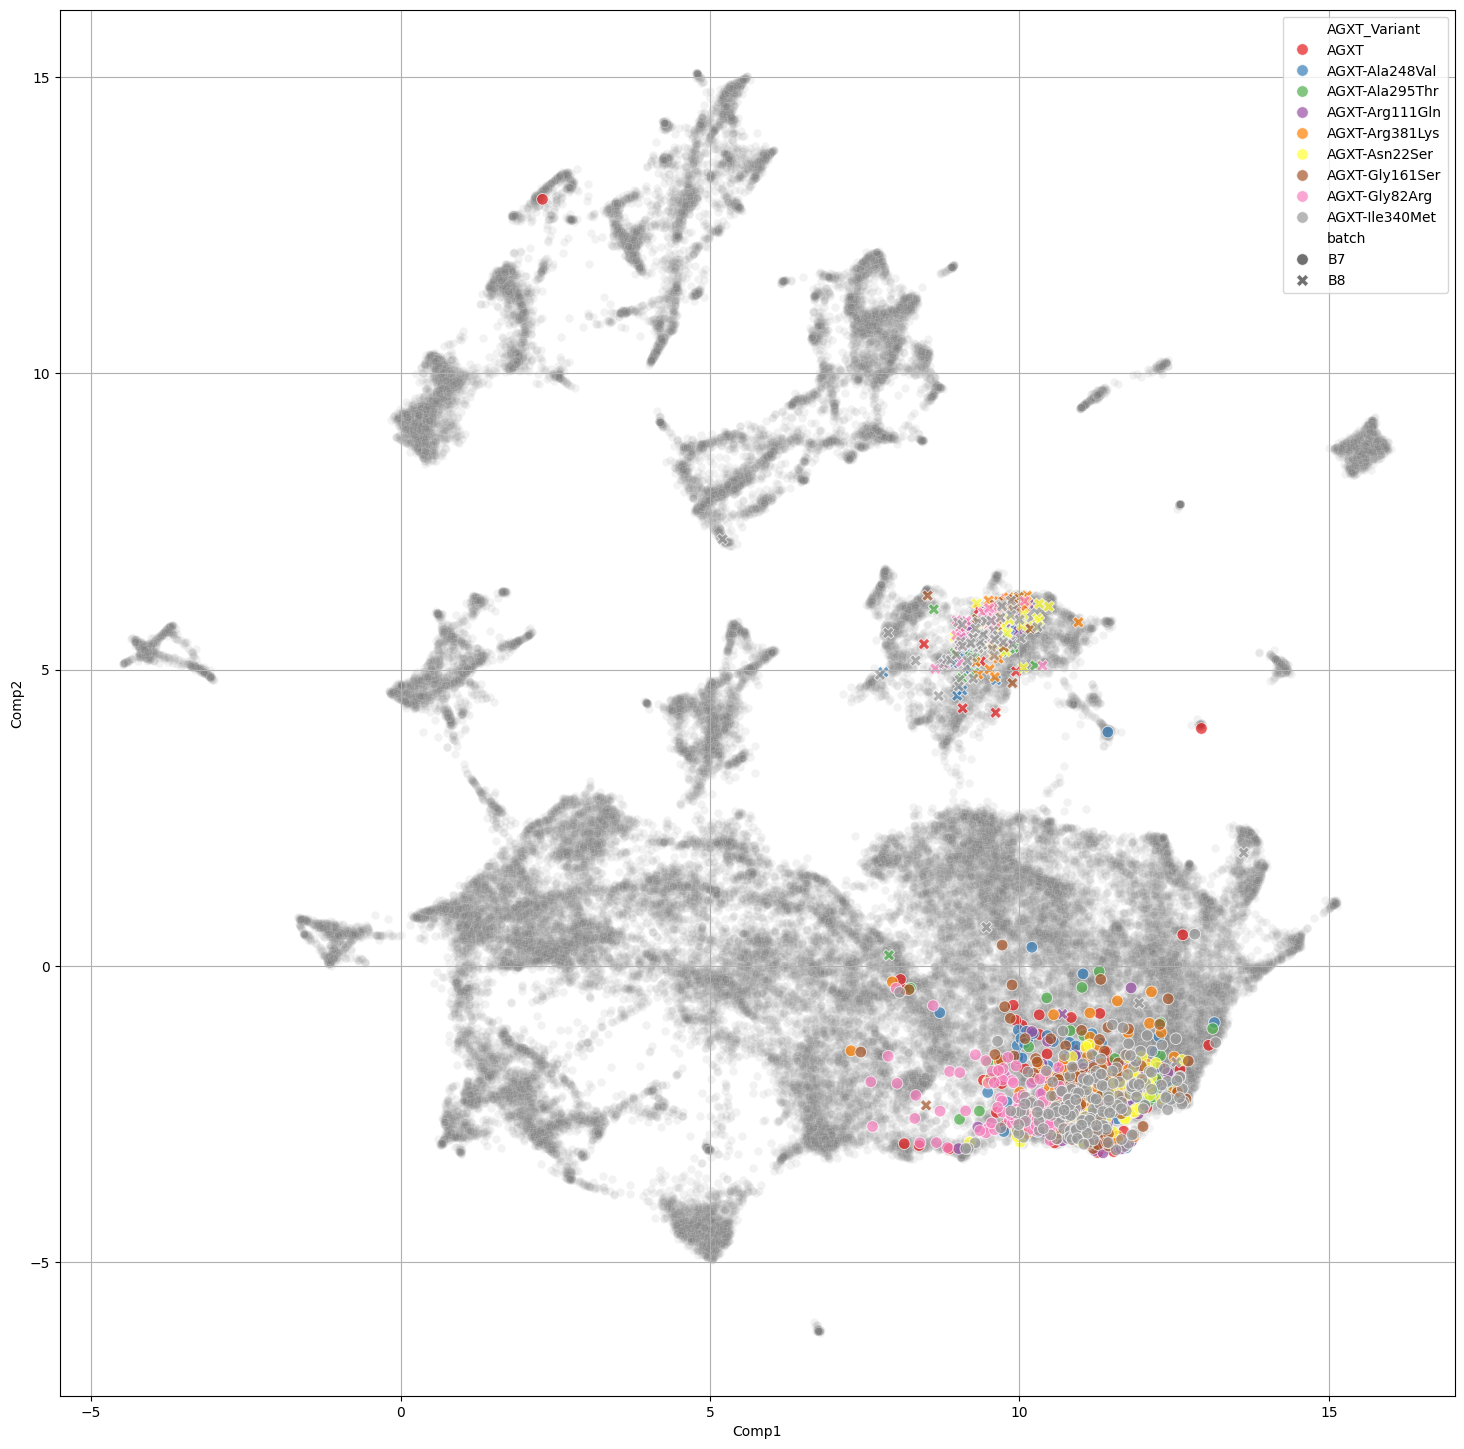

In [45]:
fig, ax = plt.subplots(1, 1, figsize=(18, 18))
ax.grid(True)

list_unique_agxt = umap_df.filter(
    (pl.col("Comp1")>10)&(pl.col("Comp1")<15)&(pl.col("Comp2")>2.5)&(pl.col("Comp2")<6)&(pl.col("Metadata_Protein").str.contains("AGXT"))
).sort(pl.col("Metadata_Protein")
).select(
    pl.col("Metadata_Protein")
).unique().sort(by="Metadata_Protein").to_series().to_numpy()

gene = "AGXT"
umap_df = umap_df.with_columns(
    pl.when(pl.col("Metadata_Protein").is_in(list(list_unique_agxt)[:9]))
    .then(pl.col("Metadata_Protein"))
    .otherwise(pl.lit("000")).alias(f"{gene}_Variant")
).sort(f"{gene}_Variant")

sns.scatterplot(umap_df.filter(pl.col(f"{gene}_Variant") == "000"), x="Comp1", y="Comp2", color="grey", alpha=.1, ax=ax)
sns.scatterplot(umap_df.filter(pl.col(f"{gene}_Variant") != "000"), x="Comp1", y="Comp2", hue=f"{gene}_Variant", style="batch", palette="Set1", ax=ax, s=70, alpha=0.7)

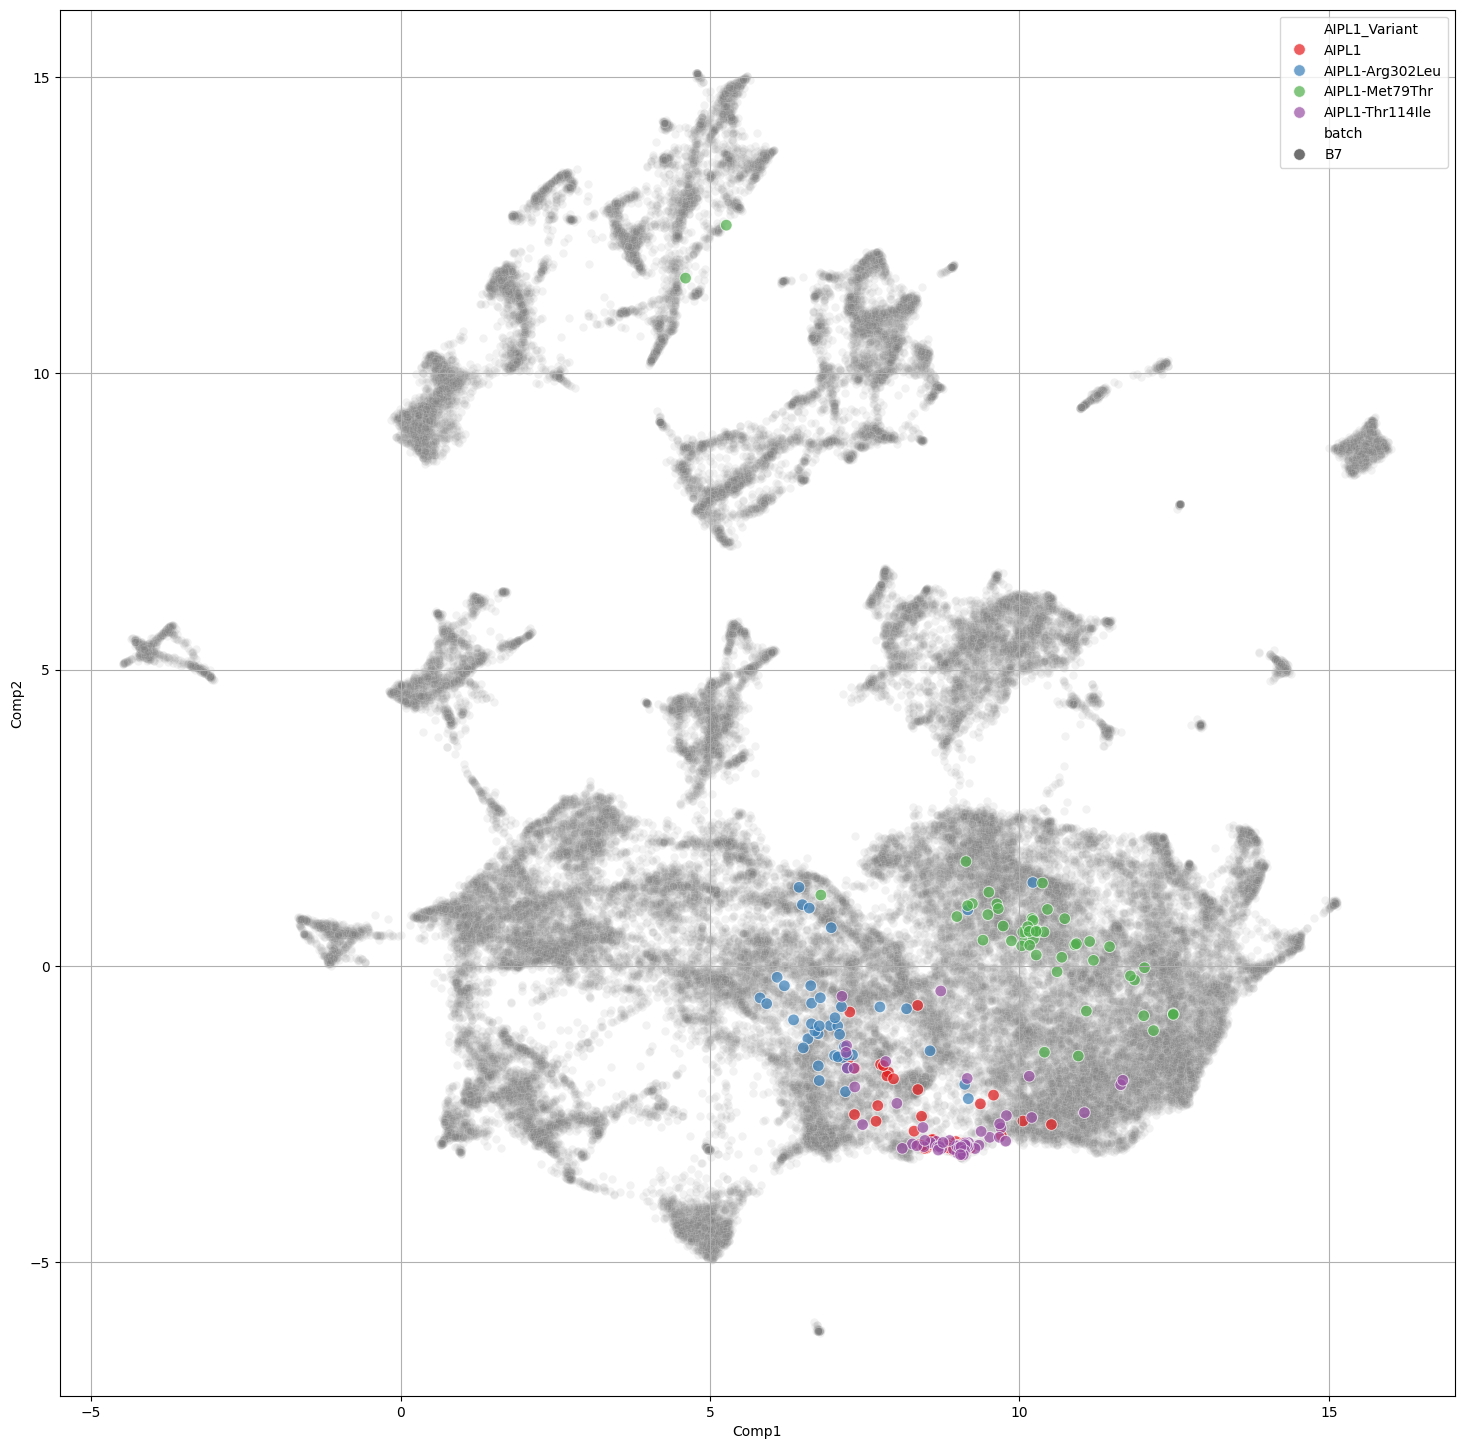

In [46]:
plot_gene_umap(umap_df, "AIPL1")

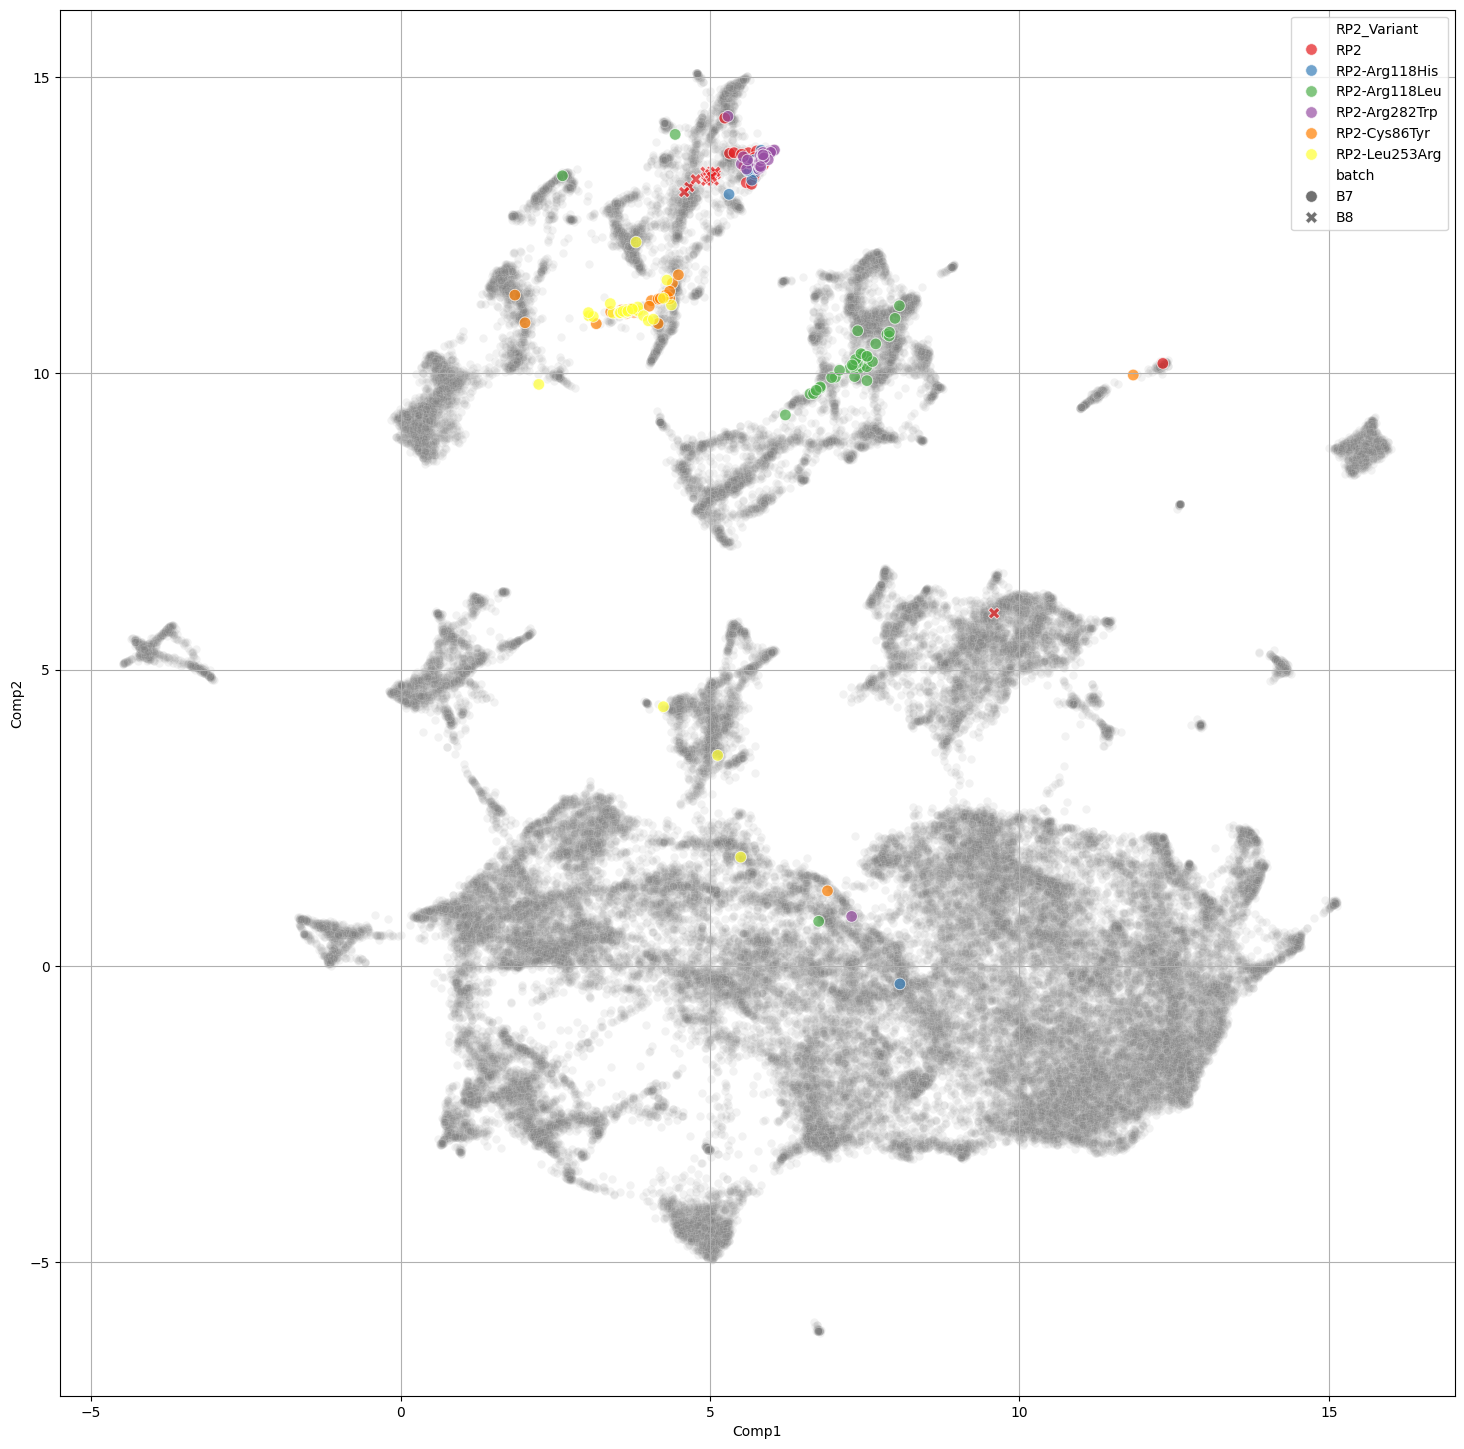

In [47]:
plot_gene_umap(umap_df, "RP2")

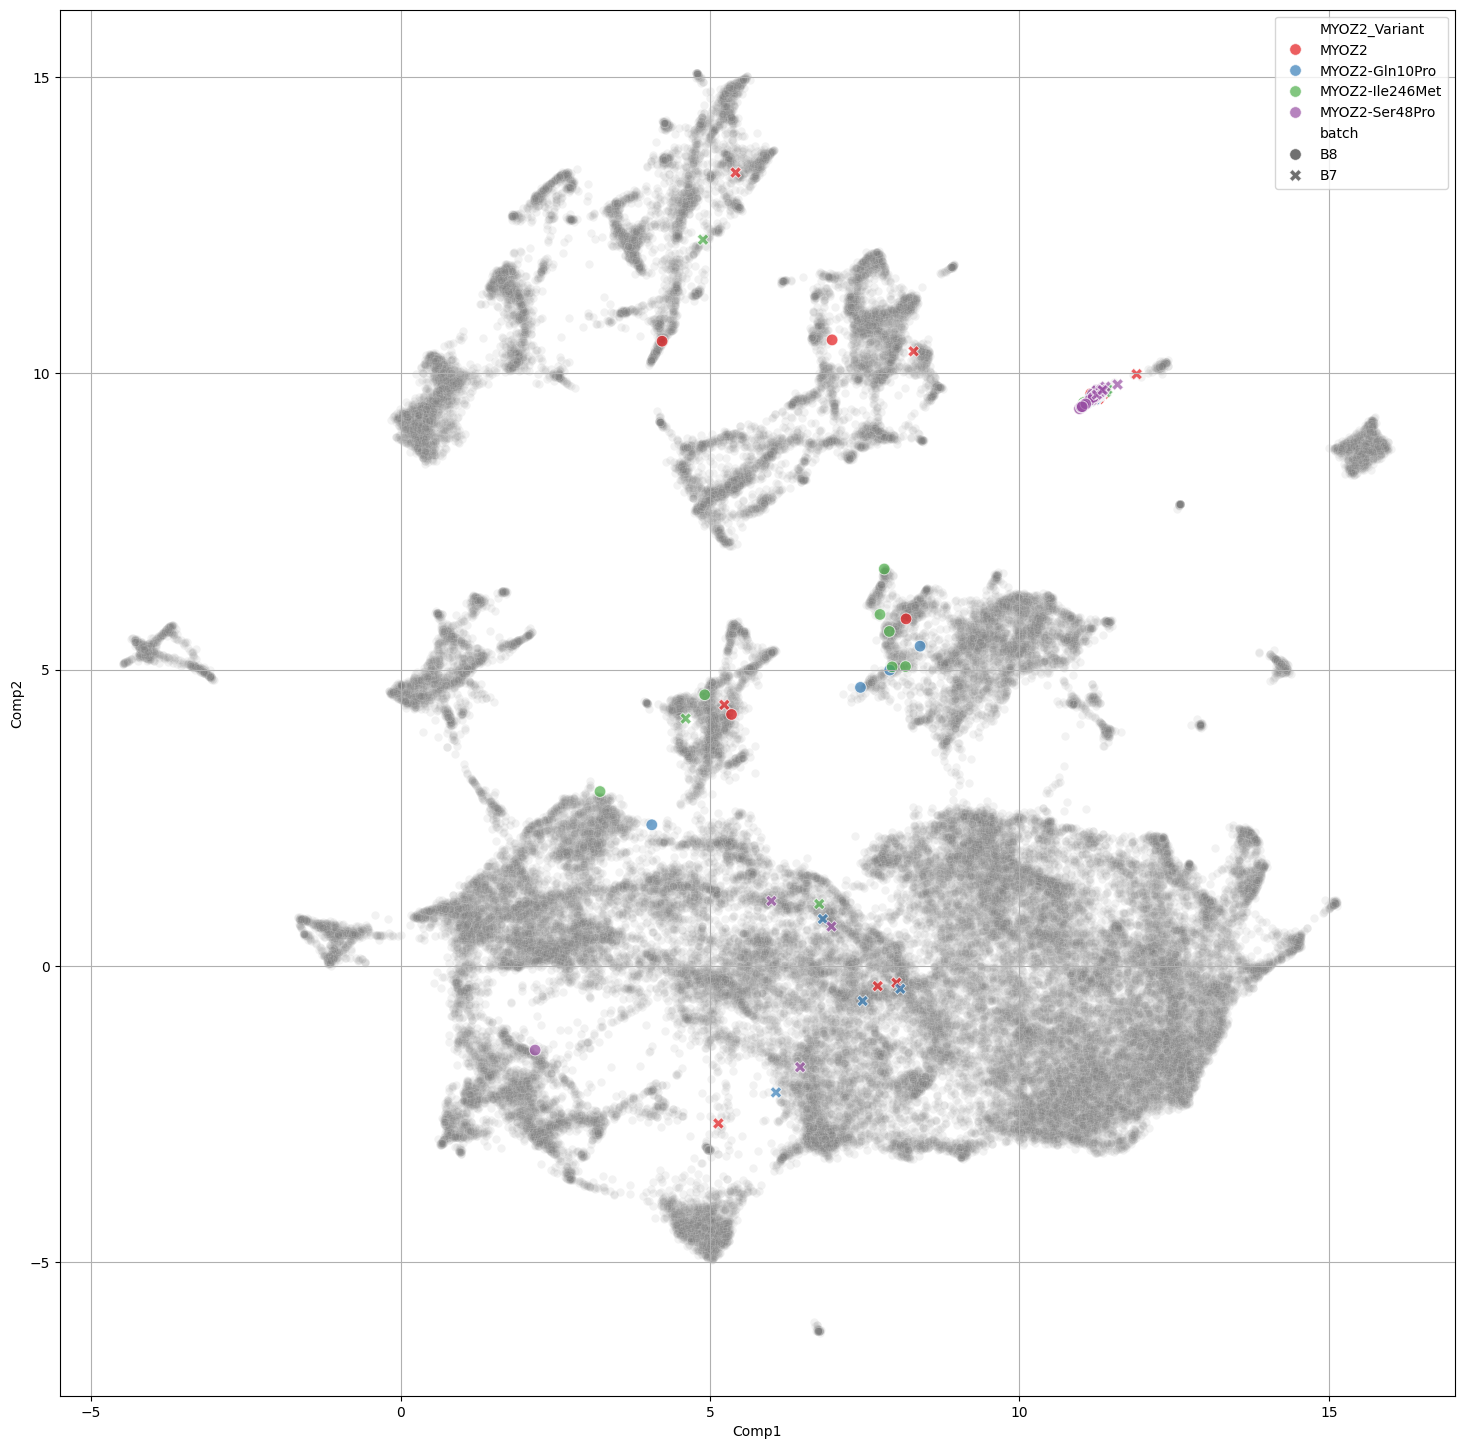

In [48]:
plot_gene_umap(umap_df, "MYOZ2")

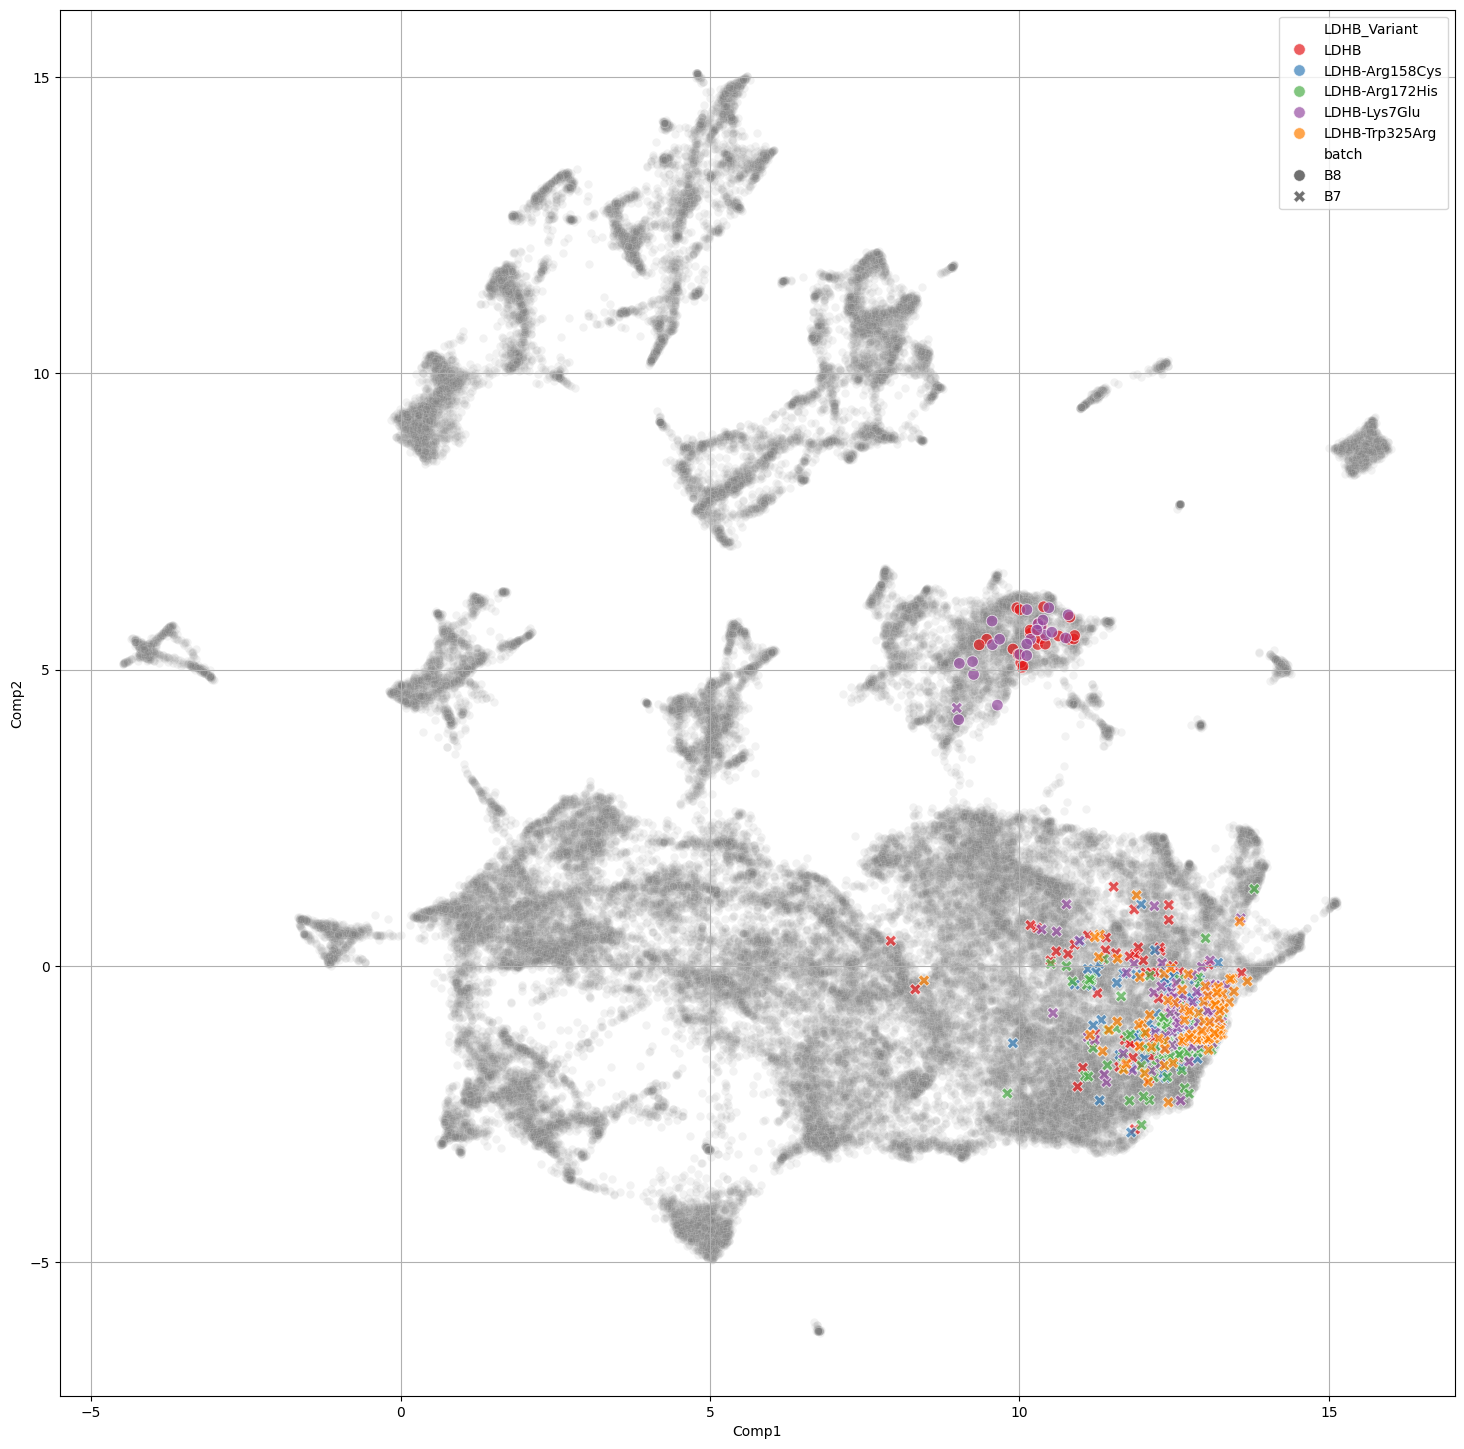

In [49]:
plot_gene_umap(umap_df, "LDHB")

## HPA subcellular annotations

In [13]:
hpa_subcell_loc = pl.read_csv("../hpa_subcellular_location_annotations/subcellular_location_data.tsv", separator="\t")
hpa_subcell_loc

umap_df_hpa = umap_df.join(hpa_subcell_loc, left_on="Gene", right_on="Gene name")
# umap_df_hpa

In [14]:
umap_df_hpa = umap_df_hpa.with_columns(
    pl.when(pl.col("Main location").str.contains(";"))
    .then(pl.lit("Multiple"))
    .otherwise(pl.col("Main location"))
    .alias("Subcell_Loc")
)
umap_df_hpa.filter(
    (pl.col("Allele_type")=="Reference")&(pl.col("Subcell_Loc")!="Multiple")&(pl.col("Additional location").is_null()&(pl.col("Reliability")=="Approved"))
)

Metadata_Protein,Metadata_CellID,Comp1,Comp2,batch,well_position,Gene,Allele_type,Gene_right,Reliability,Main location,Additional location,Extracellular location,Enhanced,Supported,Approved,Uncertain,Single-cell variation intensity,Single-cell variation spatial,Cell cycle dependency,GO id,Subcell_Loc
str,str,f32,f32,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""DMC1""","""2024_01_17_B7A1R1_P1T4_F14_120…",13.322915,-0.344944,"""B7""","""F14""","""DMC1""","""Reference""","""ENSG00000100206""","""Approved""","""Nucleoplasm""",null,null,null,null,"""Nucleoplasm""",null,null,null,null,"""Nucleoplasm (GO:0005654)""","""Nucleoplasm"""
"""MCEE""","""2024_02_01_B8A1R2_P2T4_N24_301…",2.117532,5.629408,"""B8""","""N24""","""MCEE""","""Reference""","""ENSG00000124370""","""Approved""","""Nucleoli""",null,null,null,null,"""Nucleoli""",null,"""Nucleoli""",null,null,"""Nucleoli (GO:0005730)""","""Nucleoli"""
"""SH2D1A""","""2024_01_19_B7A1R1_P4T1_C01_433…",6.383503,-3.041239,"""B7""","""C01""","""SH2D1A""","""Reference""","""ENSG00000183918""","""Approved""","""Cytosol""",null,null,null,null,"""Cytosol""",null,null,null,null,"""Cytosol (GO:0005829)""","""Cytosol"""
"""PAPSS2""","""2024_01_18_B7A1R1_P3T1_K16_230…",9.456421,-0.848352,"""B7""","""K16""","""PAPSS2""","""Reference""","""ENSG00000198682""","""Approved""","""Mitochondria""",null,null,null,null,"""Mitochondria""",null,"""Mitochondria""",null,null,"""Mitochondria (GO:0005739)""","""Mitochondria"""
"""DMC1""","""2024_01_17_B7A1R1_P1T1_F14_119…",12.136945,1.70976,"""B7""","""F14""","""DMC1""","""Reference""","""ENSG00000100206""","""Approved""","""Nucleoplasm""",null,null,null,null,"""Nucleoplasm""",null,null,null,null,"""Nucleoplasm (GO:0005654)""","""Nucleoplasm"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""COL10A1""","""2024_01_17_B7A1R1_P1T4_I24_193…",1.066366,5.035361,"""B7""","""I24""","""COL10A1""","""Reference""","""ENSG00000123500""","""Approved""","""Endoplasmic reticulum""",null,"""Predicted to be secreted""",null,null,"""Endoplasmic reticulum""",null,"""Endoplasmic reticulum""",null,null,"""Endoplasmic reticulum (GO:0005…","""Endoplasmic reticulum"""
"""FBP1""","""2024_01_17_B7A1R1_P2T3_A01_2_5…",13.127567,-0.262571,"""B7""","""A01""","""FBP1""","""Reference""","""ENSG00000165140""","""Approved""","""Mitochondria""",null,null,null,null,"""Mitochondria""",null,"""Mitochondria""",null,null,"""Mitochondria (GO:0005739)""","""Mitochondria"""
"""TH""","""2024_01_23_B7A1R1_P4T2_I12_183…",12.858655,1.392265,"""B7""","""I12""","""TH""","""Reference""","""ENSG00000180176""","""Approved""","""Cytosol""",null,null,null,null,"""Cytosol""",null,null,null,null,"""Cytosol (GO:0005829)""","""Cytosol"""


In [19]:
umap_df_hpa.filter(
    (pl.col("Allele_type")=="Reference")&(pl.col("Subcell_Loc")!="Multiple")&(pl.col("Additional location").is_null()&(pl.col("Reliability")=="Approved"))
).sort("Subcell_Loc")

Metadata_Protein,Metadata_CellID,Comp1,Comp2,batch,well_position,Gene,Allele_type,Gene_right,Reliability,Main location,Additional location,Extracellular location,Enhanced,Supported,Approved,Uncertain,Single-cell variation intensity,Single-cell variation spatial,Cell cycle dependency,GO id,Subcell_Loc
str,str,f32,f32,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""FAM187A""","""2024_01_17_B7A1R1_P1T1_J24_216…",7.928979,1.715996,"""B7""","""J24""","""FAM187A""","""Reference""","""ENSG00000214447""","""Approved""","""Acrosome""",null,null,null,null,"""Acrosome""",null,"""Acrosome""",null,null,"""Acrosome ()""","""Acrosome"""
"""FAM187A""","""2024_01_17_B7A1R1_P1T2_J24_215…",5.276966,1.786679,"""B7""","""J24""","""FAM187A""","""Reference""","""ENSG00000214447""","""Approved""","""Acrosome""",null,null,null,null,"""Acrosome""",null,"""Acrosome""",null,null,"""Acrosome ()""","""Acrosome"""
"""FAM187A""","""2024_01_17_B7A1R1_P1T4_J24_215…",8.401104,0.758812,"""B7""","""J24""","""FAM187A""","""Reference""","""ENSG00000214447""","""Approved""","""Acrosome""",null,null,null,null,"""Acrosome""",null,"""Acrosome""",null,null,"""Acrosome ()""","""Acrosome"""
"""FAM187A""","""2024_01_17_B7A1R1_P1T4_J24_215…",6.547633,1.041917,"""B7""","""J24""","""FAM187A""","""Reference""","""ENSG00000214447""","""Approved""","""Acrosome""",null,null,null,null,"""Acrosome""",null,"""Acrosome""",null,null,"""Acrosome ()""","""Acrosome"""
"""FAM187A""","""2024_01_17_B7A1R1_P1T2_J24_215…",6.368519,-0.245788,"""B7""","""J24""","""FAM187A""","""Reference""","""ENSG00000214447""","""Approved""","""Acrosome""",null,null,null,null,"""Acrosome""",null,"""Acrosome""",null,null,"""Acrosome ()""","""Acrosome"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""GYG1""","""2024_01_17_B7A1R1_P2T3_K08_222…",12.087855,0.330167,"""B7""","""K08""","""GYG1""","""Reference""","""ENSG00000163754""","""Approved""","""Vesicles""",null,null,null,null,"""Vesicles""",null,null,null,null,"""Vesicles (GO:0043231)""","""Vesicles"""
"""ACY1""","""2024_01_17_B7A1R1_P1T1_A07_62_…",10.098152,-1.744243,"""B7""","""A07""","""ACY1""","""Reference""","""ENSG00000243989""","""Approved""","""Vesicles""",null,null,null,null,"""Vesicles""",null,null,null,null,"""Vesicles (GO:0043231)""","""Vesicles"""
"""TPK1""","""2024_02_05_B8A1R2_P4T2_B01_221…",9.063273,6.146046,"""B8""","""B01""","""TPK1""","""Reference""","""ENSG00000196511""","""Approved""","""Vesicles""",null,null,null,null,"""Vesicles""",null,null,null,null,"""Vesicles (GO:0043231)""","""Vesicles"""


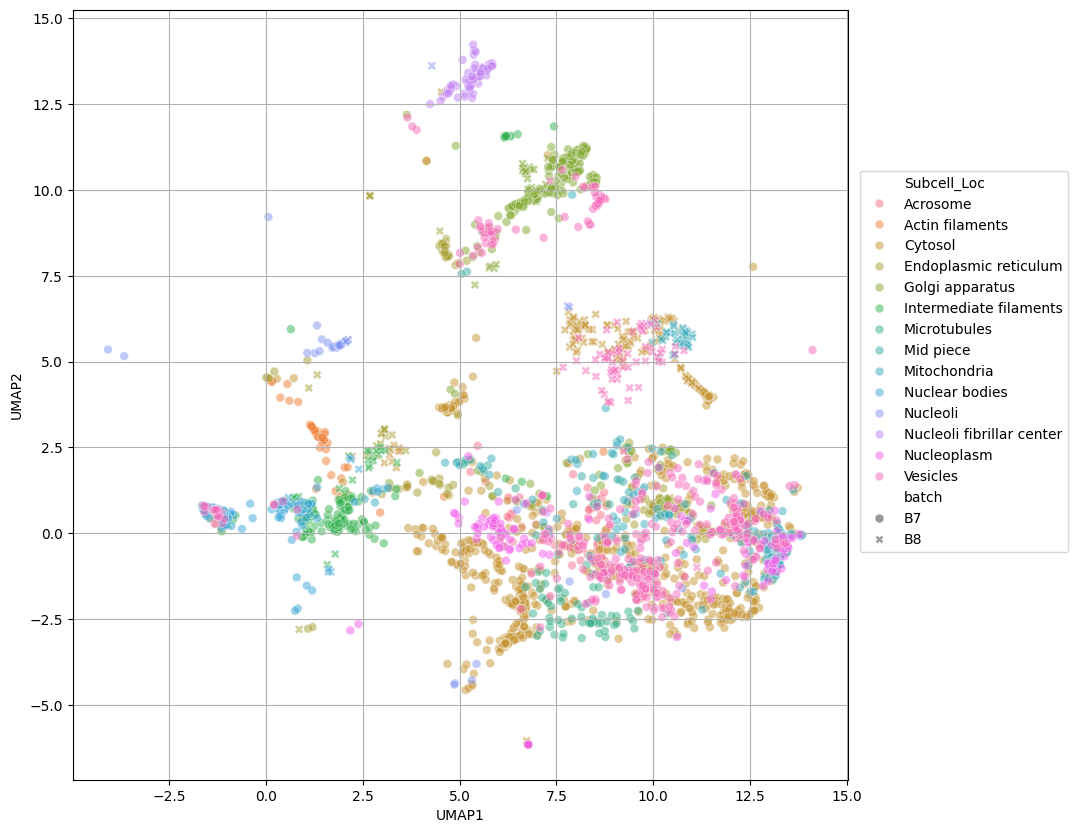

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.grid(True)

# umap_df = umap_df.with_columns(
#     pl.when(pl.col("Allele_type").is_in(list(list_unique_agxt)[:9]))
#     .then(pl.col("Metadata_Protein"))
#     .otherwise(pl.lit("000")).alias(f"{gene}_Variant")
# ).sort(f"{gene}_Variant")

# sns.scatterplot(umap_df_hpa.filter(pl.col("Allele_type") == "Allele"), x="Comp1", y="Comp2", color="grey", alpha=.1, ax=ax)
sns.scatterplot(umap_df_hpa.filter(
    (pl.col("Allele_type")=="Reference")&(pl.col("Subcell_Loc")!="Multiple")&(pl.col("Additional location").is_null()&(pl.col("Reliability")=="Approved"))
).sort("Subcell_Loc"),#.sample(fraction=.5, shuffle=True), 
x="Comp1", y="Comp2", 
hue=f"Subcell_Loc", style="batch", palette="husl", ax=ax, s=40, alpha=0.5) ## get_custom_colormap(14)
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
# ax.legend(loc='lower left', ncol=4, title="Subcellular Loc.")
leg = ax.get_legend()
leg.set_bbox_to_anchor((0.5, .8, 1.3, 0))
leg._loc = 9

Next steps:
- Reproduce their cluster analysis with GO:CC and Corum complexes. Try implement the idea that I had for spatial enrichment. 
- Adapt pooled-rare plotting functions for the Varchamp data so that I can look up specific cells based on the UMAP location.
- Make comparable UMAPs with CellProfiler features: use all same QA/QC filters, plus downsample to ~10%